# Figure 4: cell-cell communication of SIMs and emphysema progression

Panels based on data (all from the cell-cell communication tables in `data/` (Supplementary Tables 10-17, `*_ccc_*.csv`), see `00_prepare_ccc_tables.ipynb`):
- **4a** association of the MOFAtalk factors with fast vs slow progression
- **4b** scores of the progression factor per sample
- **4c** sender → receiver views with the largest variance explained by the progression factor
- **4d** SIM receptors with the most nominally significant incoming interactions
- **4e-f** per-sample scores of the best interactions into SIMs through the focus receptors TLR2 and NRP1
- **Supplementary** expression of the focus receptors in SIM pseudobulks

Statistics (mixed models on the interaction scores and factor scores, edgeR on the pseudobulks) were computed in the
cell-cell communication analysis; this notebook only draws its results. P-values are nominal (no SIM interaction
reaches FDR < 0.1).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from figure_style import DENSE_FONT_SIZE, FONT_SIZE, SMALL_FONT_SIZE, figure_size, save_panel, set_style

set_style()
plt.rcParams.update({"mathtext.fontset": "custom", "mathtext.rm": "Arial", "mathtext.it": "Arial:italic", "mathtext.bf": "Arial:bold"})  # Italic p in Arial
DATA = Path("../data")

LABEL_FONT_SIZE = 8  # Panel letters of the supplementary figure (bold)

SIM = "Macrophages_Smoking-induced"
PROGRESSION_FACTOR = "Factor1"
FOCUS_RECEPTORS = ["TLR2", "NRP1"]
EXEMPLAR_INTERACTIONS = {"TLR2": "DC1&Macrophages_Smoking-induced:HMGB1^TLR2", "NRP1": "DC2&Macrophages_Smoking-induced:VEGFA^NRP1"}

GROUP_KEY = "Emphysema Progression Type"
emphysema_progression_types = ["No Emphysema - Slow", "No Emphysema - Fast", "Emphysema - Slow", "Emphysema - Fast"]
emphysema_progression_colors = ["lightblue", "pink", "#4682B4", "#e31a1c"]
emphysema_progression_labels = ["NE-slow", "NE-fast", "E-slow", "E-fast"]  # NE: no emphysema, E: emphysema

SHORT_NAMES = {
    SIM: "SIM", "T_senescence-associated": "SAT", "Macrophages_Alveolar": "AM", "Macrophages_Alveolar_APOE": "AM-APOE",
    "Macrophages_Interstitial": "IM", "Macrophages_div": "Mac-div", "Monocytes_Classical": "cMono", "Monocytes_Non-Classical": "ncMono",
}
GRAY, LIGHT_GRAY = "#7f7f7f", "#bdbdbd"
ARROW = "→"


def short_name(cell_type):
    return SHORT_NAMES.get(cell_type, cell_type)


def panel_axes(width_mm, height_mm, left_mm, bottom_mm, top_mm=4, right_mm=1.5):
    """Figure of the given size with one axes at a fixed position in mm, so that the axes of the panels of a row align in the assembled figure.

    These panels are saved without cropping (`save_panel(..., tight=False)`), the margins must therefore hold the labels.
    """
    fig = plt.figure(figsize=figure_size(width_mm, height_mm))
    ax = fig.add_axes([left_mm / width_mm, bottom_mm / height_mm, 1 - (left_mm + right_mm) / width_mm, 1 - (bottom_mm + top_mm) / height_mm])
    return fig, ax


ROW_1_HEIGHT_MM, ROW_1_BOTTOM_MM = 50, 8   # Panels a-c: one line of tick labels and an axis label below the axes
ROW_2_HEIGHT_MM, ROW_2_BOTTOM_MM, ROW_2_TOP_MM = 58, 11, 8  # Panels d-f: two-line axis labels / titles


def plot_by_group(data, value_column, ylabel, title=None, ylim=None, ax=None):
    """Box plot per emphysema x progression group with black per-sample points (same palette as Fig. 2)."""
    ax = ax or plt.gca()
    sns.boxplot(
        data=data, x=GROUP_KEY, y=value_column, hue=GROUP_KEY, order=emphysema_progression_types, hue_order=emphysema_progression_types,
        palette=emphysema_progression_colors, showfliers=False, width=0.65, linewidth=0.5, linecolor="black", legend=False, ax=ax,
    )
    sns.swarmplot(data=data, x=GROUP_KEY, y=value_column, order=emphysema_progression_types, color="black", size=1.5, ax=ax)
    ax.set_xticks(range(len(emphysema_progression_types)), emphysema_progression_labels)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    if ylim is not None:
        ax.set_ylim(*ylim)
    if title:
        ax.set_title(title)
    sns.despine(ax=ax)

## Load the tables

In [2]:
samples = pd.read_csv(DATA / "11_ccc_samples.csv", index_col="sample_id")
factor_tests = pd.read_csv(DATA / "10_ccc_mofa_factor_progression_tests.csv", index_col=0)
r2_per_view = pd.read_csv(DATA / "12_ccc_mofa_progression_factor_r2_per_view.csv")
sim_receptor_summary = pd.read_csv(DATA / "13_ccc_sim_receptor_summary.csv", index_col=0)
exemplar_tests = pd.read_csv(DATA / "14_ccc_exemplar_interaction_tests.csv", index_col="feature")
exemplar_scores = pd.read_csv(DATA / "15_ccc_exemplar_interaction_scores.csv", index_col="sample_id").join(samples[[GROUP_KEY]])
sim_expression = pd.read_csv(DATA / "16_ccc_sim_pseudobulk_log_cpm.csv", index_col="sample_id").join(samples[[GROUP_KEY]])
sim_edger = pd.read_csv(DATA / "17_ccc_sim_edger_focus_receptors.csv", index_col="gene")
print(f"{len(samples)} samples")

56 samples


## Fig. 4a: MOFAtalk factors

t statistic of fast vs slow progression (mixed model adjusted for batch, sex, emphysema and detection rate) for each factor of the MOFAtalk
decomposition of the interaction scores. The progression factor (Factor1) is black.

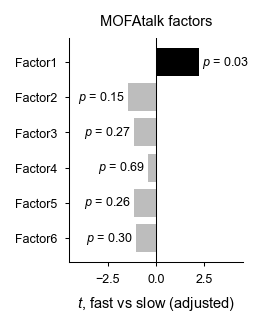

In [3]:
fig, ax = panel_axes(42, ROW_1_HEIGHT_MM, left_mm=11, bottom_mm=ROW_1_BOTTOM_MM)
factor_order = factor_tests.loc[sorted(factor_tests.index, key=lambda factor: int(factor.replace("Factor", "")))[::-1]]
plt.barh(factor_order.index, factor_order["t"], color=["black" if factor == PROGRESSION_FACTOR else LIGHT_GRAY for factor in factor_order.index])
for y, (factor, row) in enumerate(factor_order.iterrows()):
    offset = 0.15 if row["t"] >= 0 else -0.15
    plt.text(row["t"] + offset, y, f"$p$ = {row['pvalue']:.2f}", va="center", ha="left" if row["t"] >= 0 else "right", fontsize=SMALL_FONT_SIZE)
limit = np.ceil(factor_order["t"].abs().max()) + 1.5
plt.xlim(-limit, limit)
plt.axvline(0, color="black", lw=0.5)
plt.xlabel("$t$, fast vs slow (adjusted)")
plt.title("MOFAtalk factors")
sns.despine()
save_panel("Fig_4_a_mofa_factors", tight=False)

## Fig. 4b: progression factor scores per sample

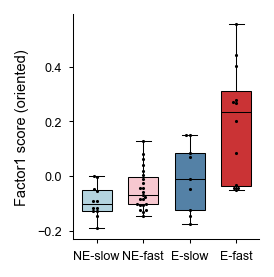

In [4]:
fig, ax = panel_axes(44, ROW_1_HEIGHT_MM, left_mm=11, bottom_mm=ROW_1_BOTTOM_MM)
plot_by_group(samples, "progression_factor", f"{PROGRESSION_FACTOR} score (oriented)")
save_panel("Fig_4_b_progression_factor_scores", tight=False)

## Fig. 4c: views with the most variance explained by the progression factor

The 20 sender → receiver views (of 328) with the largest R² of the progression factor. Views involving SIMs are black.

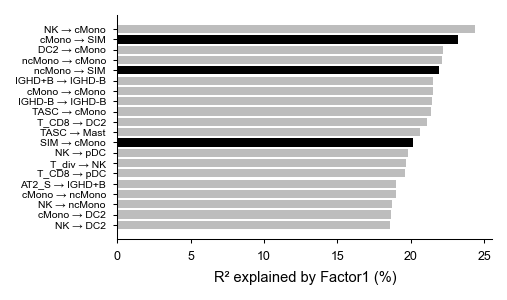

In [5]:
top_views = r2_per_view.sort_values("R2", ascending=False).head(20).iloc[::-1]
involves_sim = top_views[["source", "target"]].eq(SIM).any(axis=1)

fig, ax = panel_axes(88, ROW_1_HEIGHT_MM, left_mm=23, bottom_mm=ROW_1_BOTTOM_MM)
plt.barh(top_views["source"].map(short_name) + f" {ARROW} " + top_views["target"].map(short_name), top_views["R2"], color=np.where(involves_sim, "black", LIGHT_GRAY))
plt.xlim(0, None)
plt.yticks(fontsize=DENSE_FONT_SIZE)
plt.xlabel(f"R² explained by {PROGRESSION_FACTOR} (%)")
sns.despine()
save_panel("Fig_4_c_top_views", tight=False)

## Fig. 4d: SIM receptors with the most nominal incoming hits

The 12 receptors on SIMs with the most incoming interactions at p < 0.05: mean t of their incoming interaction scores (left) and the
edgeR statistic of the receptor gene in SIM pseudobulks (right; "complex" where the receptor is a complex without a single gene).
The table is in the order of the original analysis (by number of nominal hits; SDC4 and NCSTN, C5AR1 and ITGAV tie at 5), the first 12 are
taken, then sorted by the mean absolute value of the two statistics.

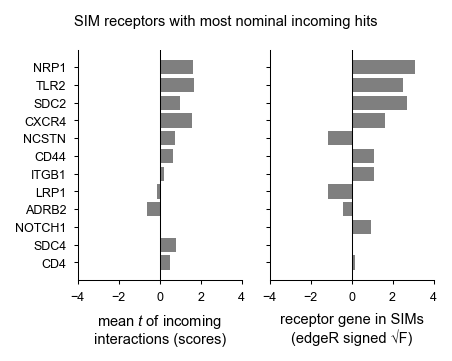

In [6]:
receptor_panel = sim_receptor_summary.head(12)
receptor_panel = receptor_panel.loc[receptor_panel[["mean_score_t", "sim_expression_t"]].abs().mean(axis=1).sort_values().index]
limit = np.ceil(np.nanmax(np.abs(receptor_panel[["mean_score_t", "sim_expression_t"]].values)))

width_mm, left_mm, gap_mm, right_mm = 72, 11, 4, 1.5
fig, ax_scores = panel_axes(width_mm, ROW_2_HEIGHT_MM, left_mm=left_mm, bottom_mm=ROW_2_BOTTOM_MM, top_mm=ROW_2_TOP_MM, right_mm=(width_mm - left_mm + gap_mm + right_mm) / 2)
ax_expression = fig.add_axes([(width_mm + left_mm + gap_mm) / 2 / width_mm, ROW_2_BOTTOM_MM / ROW_2_HEIGHT_MM, (width_mm - left_mm - gap_mm - right_mm) / 2 / width_mm, 1 - (ROW_2_BOTTOM_MM + ROW_2_TOP_MM) / ROW_2_HEIGHT_MM], sharey=ax_scores)
ax_expression.tick_params(labelleft=False)
ax_scores.barh(receptor_panel.index, receptor_panel["mean_score_t"], color=GRAY)
ax_expression.barh(receptor_panel.index, receptor_panel["sim_expression_t"].fillna(0), color=GRAY)
for ax, label in ((ax_scores, "mean $t$ of incoming\ninteractions (scores)"), (ax_expression, "receptor gene in SIMs\n(edgeR signed √F)")):
    ax.set_xlim(-limit, limit)
    ax.axvline(0, color="black", lw=0.5)
    ax.set_xlabel(label)
    sns.despine(ax=ax)
for y, receptor in enumerate(receptor_panel.index):
    if pd.isna(receptor_panel.loc[receptor, "sim_expression_t"]):
        ax_expression.text(0.15, y, "complex", va="center", fontsize=DENSE_FONT_SIZE, color=GRAY)
fig.suptitle("SIM receptors with most nominal incoming hits", fontsize=FONT_SIZE, y=1 - 2 / ROW_2_HEIGHT_MM, va="top")
save_panel("Fig_4_d_sim_receptors", tight=False)

## Fig. 4e-f: exemplar interactions into SIMs through the focus receptors

Per-sample interaction scores (1 − magnitude rank) of the most significant interaction into each focus receptor.
No p-values are shown: the interactions were selected as the strongest nominal cases and none survives multiple-testing correction.

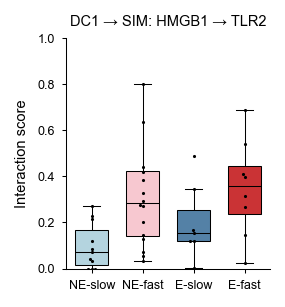

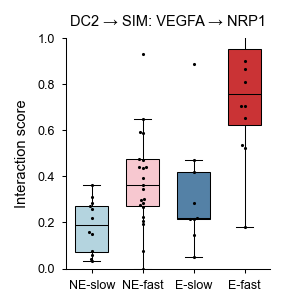

In [7]:
for letter, (receptor, feature) in zip("ef", EXEMPLAR_INTERACTIONS.items()):
    row = exemplar_tests.loc[feature]
    fig, ax = panel_axes(46, ROW_2_HEIGHT_MM, left_mm=10, bottom_mm=ROW_2_BOTTOM_MM, top_mm=ROW_2_TOP_MM)
    plot_by_group(
        exemplar_scores, feature, "Interaction score", ylim=(0, 1),
        title=f"{short_name(row['source'])} {ARROW} SIM: {row['ligand_complex']} {ARROW} {receptor}",
    )
    save_panel(f"Fig_4_{letter}_{receptor}_interaction", tight=False)

## Supplementary figure: expression of the focus receptors in SIM pseudobulks

Log1p CPM of TLR2 and NRP1 in the SIM pseudobulk of each sample; edgeR test of fast vs slow progression.

/var/folders/tc/fk7_q9y91qq3phd1l5xxg7_h0000gn/T/ipykernel_80576/519704718.py:8: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.2)


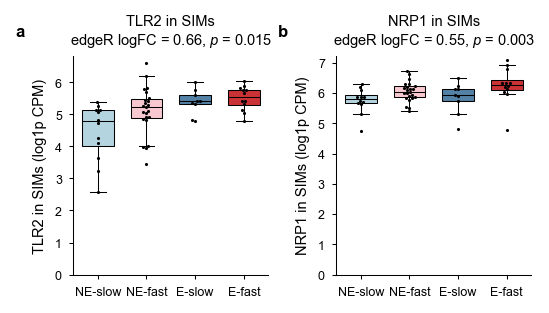

In [8]:
fig, axes = plt.subplots(1, 2, figsize=figure_size(100, 48), gridspec_kw={"wspace": 0.35})
for ax, letter, receptor in zip(axes, "ab", FOCUS_RECEPTORS):
    plot_by_group(
        sim_expression, receptor, f"{receptor} in SIMs (log1p CPM)", ylim=(0, None), ax=ax,
        title=f"{receptor} in SIMs\nedgeR logFC = {sim_edger.loc[receptor, 'logfc']:.2f}, $p$ = {sim_edger.loc[receptor, 'pvalue']:.2g}",
    )
    ax.text(-0.3, 1.08, letter, transform=ax.transAxes, fontsize=LABEL_FONT_SIZE, fontweight="bold", va="bottom", ha="left")
plt.tight_layout(pad=0.2)
save_panel("Supp_Fig_ccc_focus_receptors_expression")